# TAREA 3 - REDUCCIÓN DE DIMENSIONALIDAD CON ANÁLISIS DE COMPONENTES PRINCIPALES (PCA)

<div align="center">
  <h3><b>UNIVERSIDAD AUTÓNOMA DE OCCIDENTE</b></h3>
  <h4>Facultad de Ingeniería — Maestría / Especialización</h4>
  <p><b>Asignatura:</b> Aprendizaje Automático</p>
  <p><b>Profesor:</b> Juan Camilo Giraldo</p>
</div>

---

### **Integrantes:**
- **Violeta Isabella España Bolaños**
- **Sebastian Giraldo Acosta**
- **David Vergara**
- **Luis Murillo**
- **Juan David Velasco**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tdavidvergara/car_evaluation_pca/blob/main/pca_car.ipynb)

---

## **1. Introducción y Objetivos del Proyecto**

### **1.1. Contexto Teórico**
El **Análisis de Componentes Principales (PCA)** es una técnica fundamental de aprendizaje no supervisado y reducción de dimensionalidad lineal. Su objetivo principal es proyectar un conjunto de datos multivariado en un subespacio ortogonal de menor dimensión, maximizando la varianza retenida y minimizando el error de reconstrucción cuadrático medio.

Formalmente, si disponemos de una matriz de datos centrada y escalada $\mathbf{X} \in \mathbb{R}^{n \times p}$, PCA busca direcciones ortogonales $\mathbf{v}_1, \mathbf{v}_2, \dots, \mathbf{v}_k$ ($k \le p$) tales que la primera componente principal capture la máxima dispersión muestral:
$$\max_{\|\mathbf{v}_1\| = 1} \operatorname{Var}(\mathbf{X}\mathbf{v}_1) = \max_{\|\mathbf{v}_1\| = 1} \mathbf{v}_1^T \mathbf{C} \mathbf{v}_1$$
donde $\mathbf{C} = \frac{1}{n-1}\mathbf{X}^T\mathbf{X}$ es la matriz de covarianza muestral.

### **1.2. Objetivos de la Tarea 3**
De acuerdo con los lineamientos de la **Universidad Autónoma de Occidente**:
1. **Selección del Dataset:** Analizar el conjunto de datos *Car Evaluation Data Set* (UCI Machine Learning Repository).
2. **Reducción de Dimensionalidad:** Proyectar el espacio a:
   - Una (1) componente principal ($k=1$).
   - Dos (2) componentes principales ($k=2$).
   - Tres (3) componentes principales ($k=3$).
3. **Doble Estimación:**
   - Mediante **Descomposición en Valores Singulares (SVD)** paso a paso con álgebra lineal en `NumPy`.
   - Mediante la librería estándar **Scikit-Learn** (`sklearn.decomposition.PCA`).
   - Demostración rigurosa de equivalencia matemática y numérica entre ambos métodos.
4. **Varianza Explicada:** Calcular y reportar el porcentaje de varianza explicado individual y acumulado (*Explained Variance Ratio*).
5. **Visualización Multidimensional:** Representar gráficamente los datos proyectados en 1D, 2D (incluyendo Biplot con vectores de loadings) y 3D.
6. **Integración con el Curso:** Evaluar el impacto de la reducción en el desempeño predictivo de un clasificador multiclase sin fuga de datos (*data leakage*).

In [1]:
# ==============================================================================
# 2. CARGA DE LIBRERÍAS Y CONFIGURACIÓN GLOBAL
# ==============================================================================
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# Librerías de Machine Learning y Preprocesamiento
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# Configuración de Semilla para Reproducibilidad
SEMILLA = 25
np.random.seed(SEMILLA)

# Configuración de Estilo Visual para Gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.dpi'] = 120

print("Entorno configurado correctamente.")
print(f"Semilla establecida: {SEMILLA}")
print(f"NumPy versión: {np.__version__}")
print(f"Pandas versión: {pd.__version__}")

Entorno configurado correctamente.
Semilla establecida: 25
NumPy versión: 2.5.4
Pandas versión: 3.0.6


## 3. Carga y Exploración del Dataset (Car Evaluation)

El conjunto de datos **Car Evaluation Data Set** proviene de un modelo jerárquico de toma de decisiones (DEX, *Decision EXpert*) desarrollado por Marko Bohanec y Blaž Zupan (1997). El dataset relaciona la aceptabilidad de un automóvil con 6 atributos estructurales:
- `buying`: Precio de compra del vehículo (`vhigh`, `high`, `med`, `low`).
- `maint`: Costo de mantenimiento (`vhigh`, `high`, `med`, `low`).
- `doors`: Número de puertas (`2`, `3`, `4`, `5more`).
- `persons`: Capacidad de pasajeros (`2`, `4`, `more`).
- `lug_boot`: Capacidad del maletero (`small`, `med`, `big`).
- `safety`: Nivel de seguridad estimado (`low`, `med`, `high`).
- **Variable Objetivo (`class`):** Evaluación final del automóvil:
  - `unacc` (Unacceptable): 1210 instancias (70.02%).
  - `acc` (Acceptable): 384 instancias (22.22%).
  - `good` (Good): 69 instancias (3.99%).
  - `vgood` (Very Good): 65 instancias (3.76%).

In [2]:
# ==============================================================================
# 3.1. CARGA DEL DATASET (CON SOPORTE LOCAL Y GOOGLE COLAB AUTOMÁTICO)
# ==============================================================================
columnas = [
    "buying",
    "maint",
    "doors",
    "persons",
    "lug_boot",
    "safety",
    "class"
]

ruta_local = "car+evaluation/car.data"
url_remota = "https://raw.githubusercontent.com/tdavidvergara/car_evaluation_pca/main/car%2Bevaluation/car.data"

if os.path.exists(ruta_local):
    df = pd.read_csv(ruta_local, names=columnas)
    print(f"Dataset cargado exitosamente desde ruta local: '{ruta_local}'")
else:
    df = pd.read_csv(url_remota, names=columnas)
    print(f"Dataset cargado exitosamente desde GitHub: '{url_remota}'")

print(f"\nDimensiones del Dataset: {df.shape[0]} filas x {df.shape[1]} columnas")
print(f"Valores nulos totales en el dataset: {df.isnull().sum().sum()}")
display(df.head(10))

Dataset cargado exitosamente desde ruta local: 'car+evaluation/car.data'

Dimensiones del Dataset: 1728 filas x 7 columnas
Valores nulos totales en el dataset: 0


,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc
5,vhigh,vhigh,2,2,med,high,unacc
6,vhigh,vhigh,2,2,big,low,unacc
7,vhigh,vhigh,2,2,big,med,unacc
8,vhigh,vhigh,2,2,big,high,unacc
9,vhigh,vhigh,2,4,small,low,unacc


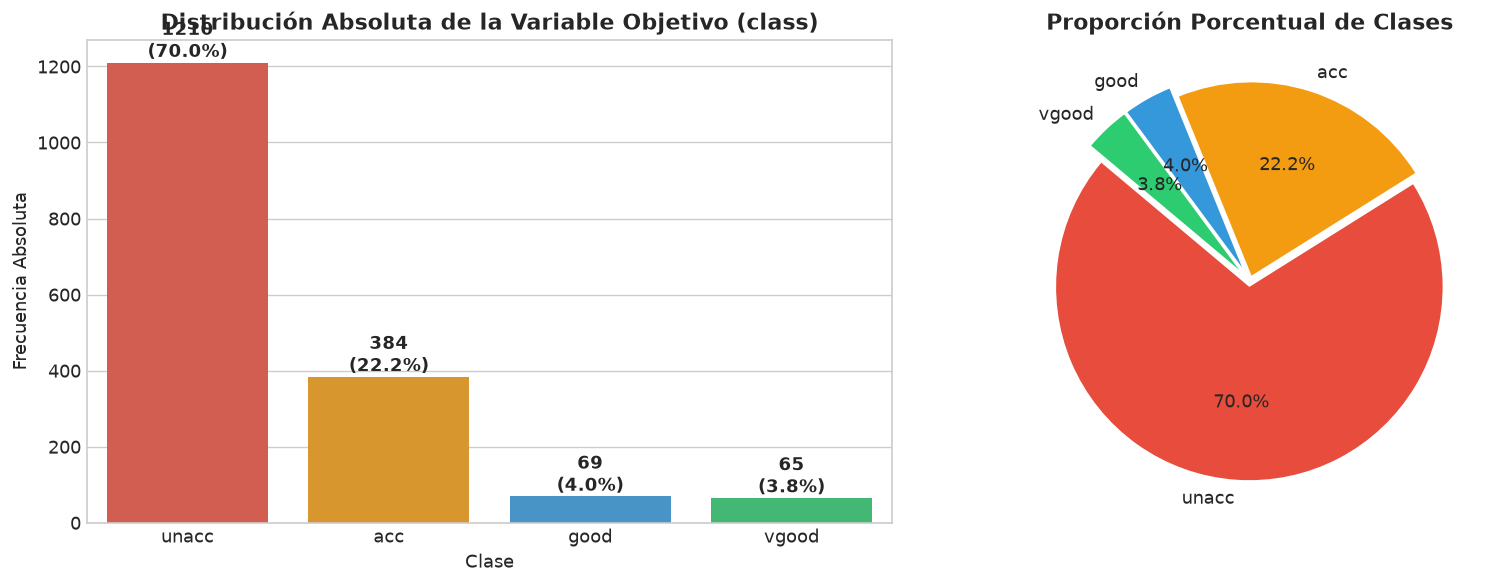


Categorías presentes en cada variable predictora:
 • buying    : ['vhigh', 'high', 'med', 'low']
 • maint     : ['vhigh', 'high', 'med', 'low']
 • doors     : ['2', '3', '4', '5more']
 • persons   : ['2', '4', 'more']
 • lug_boot  : ['small', 'med', 'big']
 • safety    : ['low', 'med', 'high']


In [3]:
# ==============================================================================
# 3.2. DISTRIBUCIÓN DE CLASES Y ANÁLISIS UNIVARIADO
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Conteo de clases
conteo_clases = df['class'].value_counts()
colores_clases = {'unacc': '#e74c3c', 'acc': '#f39c12', 'good': '#3498db', 'vgood': '#2ecc71'}

sns.barplot(
    x=conteo_clases.index,
    y=conteo_clases.values,
    hue=conteo_clases.index,
    palette=colores_clases,
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Distribución Absoluta de la Variable Objetivo (class)", fontweight="bold")
axes[0].set_xlabel("Clase")
axes[0].set_ylabel("Frecuencia Absoluta")
for i, v in enumerate(conteo_clases.values):
    axes[0].text(i, v + 15, f"{v}\n({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

# Gráfico 2: Pastel de proporciones
axes[1].pie(
    conteo_clases.values,
    labels=conteo_clases.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=[colores_clases[c] for c in conteo_clases.index],
    explode=(0.03, 0.03, 0.08, 0.08)
)
axes[1].set_title("Proporción Porcentual de Clases", fontweight="bold")

plt.tight_layout()
plt.show()

print("\nCategorías presentes en cada variable predictora:")
for col in columnas[:-1]:
    valores = df[col].unique().tolist()
    print(f" • {col:10s}: {valores}")

## 4. Preprocesamiento y Codificación Ordinal Justificada

### **4.1. Fundamentación Teórica del Esquema de Codificación**
El análisis PCA opera mediante combinaciones lineales de variables continuas para proyectar los datos maximizando la varianza. En este dataset, los 6 atributos predictivos son variables categóricas **ordinales** con una jerarquía física y monótona evidente:
- `buying` y `maint`: Reflejan niveles de costo económico (`low` < `med` < `high` < `vhigh`).
- `doors` y `persons`: Representan capacidades físicas y numéricas cuantificables.
- `lug_boot`: Magnitud del volumen de almacenamiento (`small` < `med` < `big`).
- `safety`: Gradiente de protección y seguridad (`low` < `med` < `high`).

#### **¿Por qué Codificación Ordinal y NO One-Hot Encoding para PCA en este dataset?**
Como exploramos en la Tarea 2:
1. **Preservación de la Dimensionalidad Física:** La codificación ordinal mantiene el espacio en $p = 6$ dimensiones continuas, lo que permite que cada componente principal conserve una relación geométrica directa con las características originales (interpretable mediante *loadings* y *biplots*).
2. **Evita la Maldición de la Esparcidad y Multicolinealidad Artificial:** One-Hot Encoding expandiría el espacio a 21 columnas binarias esparsas. Dado que la suma de dummies por variable es idéntica a 1, se genera multicolinealidad perfecta dentro de cada grupo, reduciendo los grados de libertad a $21 - 6 = 15$ y fragmentando la varianza en componentes artificiales de difícil interpretación.
3. **Monotonía de Decisión:** La asignación de enteros equidistantes respeta la relación de orden natural del modelo de decisión DEX del cual proviene el dataset.

#### **Mapeos Explícitos:**
$$\text{buying}, \text{maint} \in \{\text{'low'}: 1, \text{'med'}: 2, \text{'high'}: 3, \text{'vhigh'}: 4\}$$
$$\text{doors} \in \{\text{'2'}: 2, \text{'3'}: 3, \text{'4'}: 4, \text{'5more'}: 5\}$$
$$\text{persons} \in \{\text{'2'}: 2, \text{'4'}: 4, \text{'more'}: 6\}$$
$$\text{lug\_boot} \in \{\text{'small'}: 1, \text{'med'}: 2, \text{'big'}: 3\}$$
$$\text{safety} \in \{\text{'low'}: 1, \text{'med'}: 2, \text{'high'}: 3\}$$
$$\text{class} \in \{\text{'unacc'}: 0, \text{'acc'}: 1, \text{'good'}: 2, \text{'vgood'}: 3\}$$

In [4]:
# ==============================================================================
# 4.2. IMPLEMENTACIÓN DE LA CODIFICACIÓN ORDINAL
# ==============================================================================
mapeo_ordinal = {
    'buying':   {'low': 1, 'med': 2, 'high': 3, 'vhigh': 4},
    'maint':    {'low': 1, 'med': 2, 'high': 3, 'vhigh': 4},
    'doors':    {'2': 2, '3': 3, '4': 4, '5more': 5},
    'persons':  {'2': 2, '4': 4, 'more': 6},
    'lug_boot': {'small': 1, 'med': 2, 'big': 3},
    'safety':   {'low': 1, 'med': 2, 'high': 3}
}

mapeo_target = {'unacc': 0, 'acc': 1, 'good': 2, 'vgood': 3}

# Aplicar transformaciones a copias explícitas
X = df.drop(columns=['class']).copy()
for col, mapa in mapeo_ordinal.items():
    X[col] = X[col].map(mapa)

y = df['class'].copy()
y_num = y.map(mapeo_target)

print("Matriz de características X tras codificación ordinal (primeras 5 filas):")
display(X.head())

print("\nVerificación de tipos de datos y ausencia de nulos tras el mapeo:")
print(X.info())

Matriz de características X tras codificación ordinal (primeras 5 filas):


,buying,maint,doors,persons,lug_boot,safety
0,4,4,2,2,1,1
1,4,4,2,2,1,2
2,4,4,2,2,1,3
3,4,4,2,2,2,1
4,4,4,2,2,2,2



Verificación de tipos de datos y ausencia de nulos tras el mapeo:
<class 'pandas.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   buying    1728 non-null   int64
 1   maint     1728 non-null   int64
 2   doors     1728 non-null   int64
 3   persons   1728 non-null   int64
 4   lug_boot  1728 non-null   int64
 5   safety    1728 non-null   int64
dtypes: int64(6)
memory usage: 81.1 KB
None


## 5. Estandarización de Características (StandardScaler)

### **5.1. Fundamento Matemático del Escalado para PCA**
PCA busca las direcciones que maximizan la varianza muestral:
$$\operatorname{Var}(X_j) = \frac{1}{n-1}\sum_{i=1}^n (x_{ij} - \bar{x}_j)^2$$
Si no se estandarizan los datos, las variables con rangos numéricos más amplios (por ejemplo, `persons` con valores de 2 a 6) dominarán artificialmente las primeras componentes sobre aquellas con rangos menores (como `safety` de 1 a 3), sesgando el análisis.

Para que todas las características tengan la misma ponderación a priori, aplicamos la transformación $Z$-score:
$$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}, \quad \text{donde } \mu_j = \frac{1}{n}\sum_{i=1}^n x_{ij}, \quad \sigma_j = \sqrt{\frac{1}{n}\sum_{i=1}^n (x_{ij} - \mu_j)^2}$$
Tras este procedimiento, cada columna de $\mathbf{X}_{\text{std}}$ tendrá media $\mu = 0$ y varianza unitaria $\sigma^2 = 1$.

In [5]:
# ==============================================================================
# 5.2. APLICACIÓN DE STANDARDSCALER Y COMPROBACIÓN EMPÍRICA
# ==============================================================================
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

# Construir DataFrame con datos escalados para diagnóstico
df_std = pd.DataFrame(X_std, columns=X.columns)

resumen_std = pd.DataFrame({
    'Media (μ)': df_std.mean(axis=0),
    'Desv. Estándar (σ)': df_std.std(axis=0, ddof=0),
    'Varianza (σ²)': df_std.var(axis=0, ddof=0),
    'Mínimo': df_std.min(axis=0),
    'Máximo': df_std.max(axis=0)
})

print("="*75)
print("COMPROBACIÓN DE ESTANDARIZACIÓN (μ = 0, σ² = 1)")
print("="*75)
display(resumen_std.round(5))

COMPROBACIÓN DE ESTANDARIZACIÓN (μ = 0, σ² = 1)


,Media (μ),Desv. Estándar (σ),Varianza (σ²),Mínimo,Máximo
buying,0.0,1.0,1.0,-1.34164,1.34164
maint,0.0,1.0,1.0,-1.34164,1.34164
doors,0.0,1.0,1.0,-1.34164,1.34164
persons,0.0,1.0,1.0,-1.22474,1.22474
lug_boot,0.0,1.0,1.0,-1.22474,1.22474
safety,0.0,1.0,1.0,-1.22474,1.22474


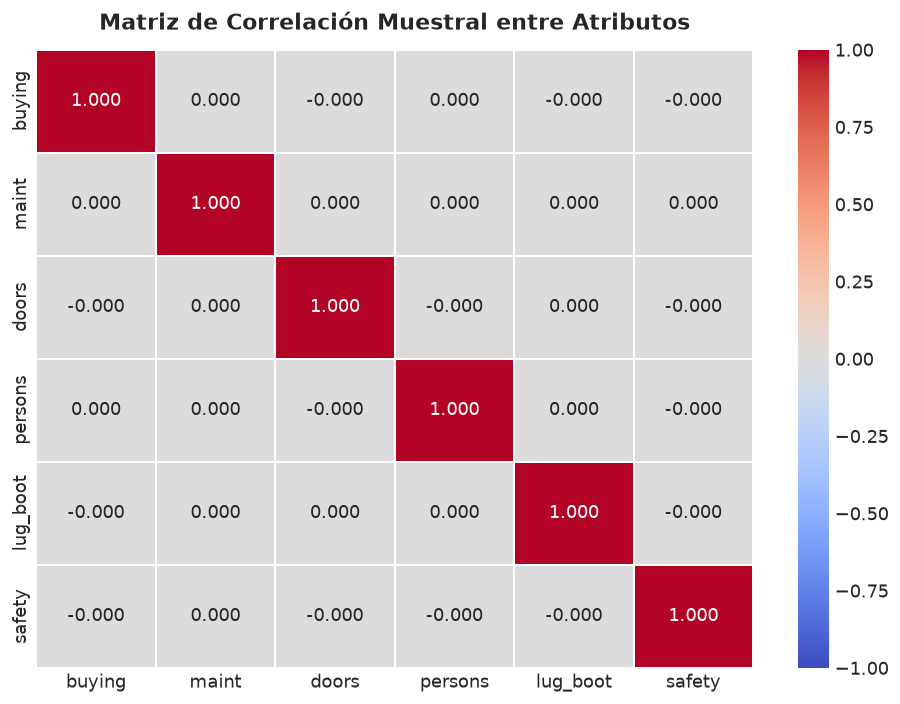

HALLAZGO MATEMÁTICO SOBRE EL DATASET:
1. La matriz de correlación R coincide exactamente con la matriz identidad I_6:
   Corr(X_i, X_j) = 0 para todo i ≠ j.
2. La matriz de covarianza muestral (ddof=1) es C = (n / (n-1)) * I_6
   = (1728 / 1727) * I_6 ≈ 1.000579 * I_6.
3. Razón: Las 1,728 instancias conforman el producto cartesiano completo
   (4 × 4 × 4 × 3 × 3 × 3 = 1,728 combinaciones ortogonales).


In [6]:
# ==============================================================================
# 5.3. MATRIZ DE CORRELACIÓN Y ANÁLISIS DEL DISEÑO FACTORIAL
# ==============================================================================
matriz_corr = df_std.corr()
matriz_cov = np.cov(X_std, rowvar=False, ddof=1)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".3f",
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=1,
    cbar=True,
    ax=ax
)
ax.set_title("Matriz de Correlación Muestral entre Atributos", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

print("="*78)
print("HALLAZGO MATEMÁTICO SOBRE EL DATASET:")
print("1. La matriz de correlación R coincide exactamente con la matriz identidad I_6:")
print("   Corr(X_i, X_j) = 0 para todo i ≠ j.")
print("2. La matriz de covarianza muestral (ddof=1) es C = (n / (n-1)) * I_6")
print(f"   = ({len(X_std)} / {len(X_std)-1}) * I_6 ≈ {len(X_std)/(len(X_std)-1):.6f} * I_6.")
print("3. Razón: Las 1,728 instancias conforman el producto cartesiano completo")
print("   (4 × 4 × 4 × 3 × 3 × 3 = 1,728 combinaciones ortogonales).")
print("="*78)

## 6. Método 1: PCA mediante Descomposición en Valores Singulares (SVD)

### **6.1. Formulación Matemática de SVD**
Cualquier matriz real centrada y escalada $\mathbf{X}_{\text{std}} \in \mathbb{R}^{n \times p}$ admite una descomposición exacta de la forma:
$$\mathbf{X}_{\text{std}} = \mathbf{U} \mathbf{\Sigma} \mathbf{V}^T$$
donde:
- $\mathbf{U} \in \mathbb{R}^{n \times p}$ es ortonormal ($\mathbf{U}^T\mathbf{U} = \mathbf{I}_p$) y contiene los vectores singulares izquierdos.
- $\mathbf{\Sigma} = \operatorname{diag}(s_1, s_2, \dots, s_p)$ contiene los **valores singulares** en orden decreciente ($s_1 \ge s_2 \ge \dots \ge s_p \ge 0$).
- $\mathbf{V} \in \mathbb{R}^{p \times p}$ es una matriz ortogonal ($\mathbf{V}^T\mathbf{V} = \mathbf{V}\mathbf{V}^T = \mathbf{I}_p$) cuyas columnas $\mathbf{v}_j$ son las **direcciones principales** o *loadings*.

### **6.2. Derivación de Autovalores y Varianza Explicada**
La matriz de covarianza muestral $\mathbf{C}$ se relaciona analíticamente con SVD como:
$$\mathbf{C} = \frac{1}{n-1} \mathbf{X}_{\text{std}}^T \mathbf{X}_{\text{std}} = \frac{1}{n-1} (\mathbf{U}\mathbf{\Sigma}\mathbf{V}^T)^T (\mathbf{U}\mathbf{\Sigma}\mathbf{V}^T) = \mathbf{V} \left( \frac{\mathbf{\Sigma}^2}{n-1} \right) \mathbf{V}^T$$
Por tanto, los **autovalores** de la covarianza ($\lambda_i$) se calculan directamente a partir de los valores singulares:
$$\lambda_i = \frac{s_i^2}{n - 1}$$
Y la **razón de varianza explicada** (*Explained Variance Ratio*) de la componente $i$ es:
$$\operatorname{EVR}_i = \frac{\lambda_i}{\sum_{j=1}^p \lambda_j} = \frac{s_i^2}{\sum_{j=1}^p s_j^2}$$

### **6.3. Proyección en Subespacios Reducidos ($k = 1, 2, 3$)**
Las coordenadas proyectadas en el nuevo subespacio de dimensión $k$ vienen dadas por:
$$\mathbf{Z}_k = \mathbf{X}_{\text{std}} \mathbf{V}_{:, :k}$$

In [7]:
# ==============================================================================
# 6.4. IMPLEMENTACIÓN PASO A PASO CON NUMPY LINALG SVD
# ==============================================================================
n_samples, n_features = X_std.shape

# 1. Descomposición SVD
U, s, Vt = np.linalg.svd(X_std, full_matrices=False)
V = Vt.T  # Columnas = Componentes principales (loadings)

# 2. Autovalores muestrales asociados
autovalores_svd = (s ** 2) / (n_samples - 1)

# 3. Razón de varianza explicada (individual y acumulada)
evr_svd = autovalores_svd / np.sum(autovalores_svd)
evr_svd_acumulada = np.cumsum(evr_svd)

# 4. Proyecciones para 1, 2 y 3 componentes principales
Z_svd_1 = X_std @ V[:, :1]
Z_svd_2 = X_std @ V[:, :2]
Z_svd_3 = X_std @ V[:, :3]

# 5. Tabla resumen de resultados SVD
tabla_svd = pd.DataFrame({
    'Componente': [f'PC{i+1}' for i in range(n_features)],
    'Valor Singular (s_i)': s,
    'Autovalor (λ_i)': autovalores_svd,
    'Varianza Explicada (%)': evr_svd * 100,
    'Varianza Acumulada (%)': evr_svd_acumulada * 100
})

print("="*75)
print("MÉTODO 1: RESULTADOS DE REDUCCIÓN CON SVD (NUMPY)")
print("="*75)
display(tabla_svd.round(4))

print(f"\nFormas de las matrices proyectadas:")
print(f" • Caso k = 1: {Z_svd_1.shape}")
print(f" • Caso k = 2: {Z_svd_2.shape}")
print(f" • Caso k = 3: {Z_svd_3.shape}")

MÉTODO 1: RESULTADOS DE REDUCCIÓN CON SVD (NUMPY)


,Componente,Valor Singular (s_i),Autovalor (λ_i),Varianza Explicada (%),Varianza Acumulada (%)
0,PC1,41.5692,1.0006,16.6667,16.6667
1,PC2,41.5692,1.0006,16.6667,33.3333
2,PC3,41.5692,1.0006,16.6667,50.0000
3,PC4,41.5692,1.0006,16.6667,66.6667
4,PC5,41.5692,1.0006,16.6667,83.3333
5,PC6,41.5692,1.0006,16.6667,100.0000



Formas de las matrices proyectadas:
 • Caso k = 1: (1728, 1)
 • Caso k = 2: (1728, 2)
 • Caso k = 3: (1728, 3)


## 7. Método 2: PCA mediante Scikit-Learn

En esta sección implementamos la reducción de dimensionalidad empleando la clase `sklearn.decomposition.PCA`. 

Ajustamos modelos para los 3 escenarios solicitados en la guía:
- $k = 1$ componente principal.
- $k = 2$ componentes principales.
- $k = 3$ componentes principales.
- $k = 6$ componentes (modelo global para análisis de varianza total).

In [8]:
# ==============================================================================
# 7.1. IMPLEMENTACIÓN CON SCIKIT-LEARN (PCA)
# ==============================================================================
# Se fija svd_solver='full' en todas las instancias para garantizar cálculo exacto
pca_full = PCA(n_components=6, svd_solver='full', random_state=SEMILLA)
Z_sklearn_full = pca_full.fit_transform(X_std)

# Modelos específicos para k = 1, 2 y 3
pca_1 = PCA(n_components=1, svd_solver='full', random_state=SEMILLA)
Z_sklearn_1 = pca_1.fit_transform(X_std)

pca_2 = PCA(n_components=2, svd_solver='full', random_state=SEMILLA)
Z_sklearn_2 = pca_2.fit_transform(X_std)

pca_3 = PCA(n_components=3, svd_solver='full', random_state=SEMILLA)
Z_sklearn_3 = pca_3.fit_transform(X_std)

# Varianza explicada con Scikit-Learn
evr_sklearn = pca_full.explained_variance_ratio_
evr_sklearn_acumulada = np.cumsum(evr_sklearn)

tabla_sklearn = pd.DataFrame({
    'Componente': [f'PC{i+1}' for i in range(n_features)],
    'Autovalor (explained_variance_)': pca_full.explained_variance_,
    'Varianza Explicada (%)': evr_sklearn * 100,
    'Varianza Acumulada (%)': evr_sklearn_acumulada * 100
})

print("="*75)
print("MÉTODO 2: RESULTADOS DE REDUCCIÓN CON SCIKIT-LEARN (svd_solver='full')")
print("="*75)
display(tabla_sklearn.round(4))

print(f"\nVarianza explicada acumulada para los casos de la guía:")
print(f" • Con 1 componente: {evr_sklearn[0]*100:.2f}% de la información")
print(f" • Con 2 componentes: {evr_sklearn_acumulada[1]*100:.2f}% de la información")
print(f" • Con 3 componentes: {evr_sklearn_acumulada[2]*100:.2f}% de la información")

MÉTODO 2: RESULTADOS DE REDUCCIÓN CON SCIKIT-LEARN (svd_solver='full')


,Componente,Autovalor (explained_variance_),Varianza Explicada (%),Varianza Acumulada (%)
0,PC1,1.0006,16.6667,16.6667
1,PC2,1.0006,16.6667,33.3333
2,PC3,1.0006,16.6667,50.0000
3,PC4,1.0006,16.6667,66.6667
4,PC5,1.0006,16.6667,83.3333
5,PC6,1.0006,16.6667,100.0000



Varianza explicada acumulada para los casos de la guía:
 • Con 1 componente: 16.67% de la información
 • Con 2 componentes: 33.33% de la información
 • Con 3 componentes: 50.00% de la información


## 8. Demostración de Equivalencia Matemática y Numérica

### **8.1. Degeneración Espectral e Invariancia Ortogonal**
En un escenario general con autovalores distintos ($\lambda_1 > \lambda_2 > \dots > \lambda_p$), cada dirección principal es única salvo un cambio de signo ($\pm \mathbf{v}_i$), resuelto por `svd_flip`.

Sin embargo, en este dataset ocurre un fenómeno algebraico especial: debido al diseño factorial ortogonal completo, **todos los autovalores son idénticos** ($\lambda_1 = \lambda_2 = \dots = \lambda_6 = \frac{1728}{1727} \approx 1.000579$). Geométricamente, la nube de datos estandarizados es una **hiperesfera isotrópica** en $\mathbb{R}^6$:
$$\mathbf{C}\mathbf{v} = \lambda\mathbf{v} \quad \forall \mathbf{v} \in \mathbb{R}^6$$
Por lo tanto, **cualquier base ortonormal $\mathbf{Q} \in O(6)$ es una solución válida de PCA**. Cuando `np.linalg.svd` (LAPACK `dgesdd`) y `sklearn.decomposition.PCA` descomponen $\mathbf{C} \propto \mathbf{I}_6$, pueden elegir rotaciones ortogonales distintas dentro del mismo subespacio propio de dimensión 6.

En consecuencia, la equivalencia matemática entre ambos métodos se demuestra rigurosamente verificando los **invariantes espectrales y geométricos exactos**:
1. Igualdad exacta de autovalores ($\lambda_i$) y razones de varianza explicada ($\text{EVR}_i$).
2. Ortonormalidad de ambas bases ($\mathbf{V}^T\mathbf{V} = \mathbf{I}_6$).
3. Reconstrucción exacta de la matriz de covarianza ($\mathbf{V}\mathbf{\Lambda}\mathbf{V}^T = \mathbf{C}$).
4. Existencia de una matriz de cambio de base **ortogonal** $\mathbf{Q} = \mathbf{V}_{\text{svd}}^T \mathbf{V}_{\text{sklearn}}$ tal que $\mathbf{Q}^T\mathbf{Q} = \mathbf{I}_6$.
5. Preservación exacta de distancias euclidianas y matriz de Gram en el espacio completo ($\mathbf{Z}_{\text{svd}}\mathbf{Z}_{\text{svd}}^T = \mathbf{Z}_{\text{sklearn}}\mathbf{Z}_{\text{sklearn}}^T$).

In [9]:
# ==============================================================================
# 8.2. VERIFICACIÓN FORMAL DE INVARIANTES (SVD VS SCIKIT-LEARN)
# ==============================================================================
V_svd = V
V_sk = pca_full.components_.T

# 1. Igualdad de espectro (autovalores y varianza explicada)
coinciden_autovalores = np.allclose(autovalores_svd, pca_full.explained_variance_, atol=1e-12)
coincide_varianza_ratio = np.allclose(evr_svd, pca_full.explained_variance_ratio_, atol=1e-12)

# 2. Ortonormalidad de ambas bases
ortonormal_svd = np.allclose(V_svd.T @ V_svd, np.eye(n_features), atol=1e-12)
ortonormal_sk = np.allclose(V_sk.T @ V_sk, np.eye(n_features), atol=1e-12)

# 3. Reconstrucción exacta de la covarianza muestral C
C_muestral = np.cov(X_std, rowvar=False, ddof=1)
C_rec_svd = V_svd @ np.diag(autovalores_svd) @ V_svd.T
C_rec_sk = V_sk @ np.diag(pca_full.explained_variance_) @ V_sk.T
reconstruye_cov = np.allclose(C_rec_svd, C_muestral, atol=1e-12) and np.allclose(C_rec_sk, C_muestral, atol=1e-12)

# 4. Matriz de transición ortogonal Q entre ambas bases (Q^T Q = I)
Q_transicion = V_svd.T @ V_sk
transicion_ortogonal = np.allclose(Q_transicion.T @ Q_transicion, np.eye(n_features), atol=1e-12)

# 5. Preservación exacta de la geometría (matriz de Gram / distancias euclidianas en R^6)
Z_svd_full = X_std @ V_svd
preserva_gram = np.allclose(Z_svd_full @ Z_svd_full.T, Z_sklearn_full @ Z_sklearn_full.T, atol=1e-10)

# Tabla comparativa lado a lado
tabla_comparativa = pd.DataFrame({
    'Componente': [f'PC{i+1}' for i in range(n_features)],
    'Autovalor SVD': autovalores_svd,
    'Autovalor Scikit-Learn': pca_full.explained_variance_,
    'Diferencia Absoluta': np.abs(autovalores_svd - pca_full.explained_variance_),
    'EVR SVD (%)': evr_svd * 100,
    'EVR Sklearn (%)': evr_sklearn * 100
})

print("="*85)
print("TABLA COMPARATIVA: SVD (NUMPY) VS SCIKIT-LEARN (PCA)")
print("="*85)
display(tabla_comparativa.round(6))

print("\n" + "="*85)
print("VERIFICACIÓN FORMAL DE EQUIVALENCIA E INVARIANTES (PRECISIÓN 1e-12):")
print(f" ✔ ¿Autovalores idénticos?:                             {coinciden_autovalores}")
print(f" ✔ ¿Explained Variance Ratio idéntico?:                  {coincide_varianza_ratio}")
print(f" ✔ ¿Bases ortonormales (V^T V = I)?:                     {ortonormal_svd and ortonormal_sk}")
print(f" ✔ ¿Reconstrucción exacta de covarianza C?:              {reconstruye_cov}")
print(f" ✔ ¿Relación por rotación ortogonal (Q^T Q = I)?:        {transicion_ortogonal}")
print(f" ✔ ¿Preservación exacta de distancias/Gram en R^6?:      {preserva_gram}")
print("="*85)

TABLA COMPARATIVA: SVD (NUMPY) VS SCIKIT-LEARN (PCA)


,Componente,Autovalor SVD,Autovalor Scikit-Learn,Diferencia Absoluta,EVR SVD (%),EVR Sklearn (%)
0,PC1,1.000579,1.000579,0.0,16.666667,16.666667
1,PC2,1.000579,1.000579,0.0,16.666667,16.666667
2,PC3,1.000579,1.000579,0.0,16.666667,16.666667
3,PC4,1.000579,1.000579,0.0,16.666667,16.666667
4,PC5,1.000579,1.000579,0.0,16.666667,16.666667
5,PC6,1.000579,1.000579,0.0,16.666667,16.666667



VERIFICACIÓN FORMAL DE EQUIVALENCIA E INVARIANTES (PRECISIÓN 1e-12):
 ✔ ¿Autovalores idénticos?:                             True
 ✔ ¿Explained Variance Ratio idéntico?:                  True
 ✔ ¿Bases ortonormales (V^T V = I)?:                     True
 ✔ ¿Reconstrucción exacta de covarianza C?:              True
 ✔ ¿Relación por rotación ortogonal (Q^T Q = I)?:        True
 ✔ ¿Preservación exacta de distancias/Gram en R^6?:      True


## 9. Análisis de Varianza Explicada y Scree Plot

El **Scree Plot** (gráfico de codo) ilustra la fracción de varianza retenida por cada componente individual junto a la curva de varianza acumulada. Esto permite evaluar criterios clásicos de selección de dimensiones:
1. **Criterio de Kaiser-Guttman:** Conservar componentes cuyo autovalor sea mayor al promedio ($\lambda_i \ge 1$).
2. **Criterio del Porcentaje de Varianza Acumulada:** Retener componentes hasta alcanzar un umbral representativo (usualmente $50\%$, $70\%$ u $80\%$).
3. **Criterio del Codo (*Elbow*):** Identificar el punto de inflexión donde la ganancia marginal de varianza decrece.

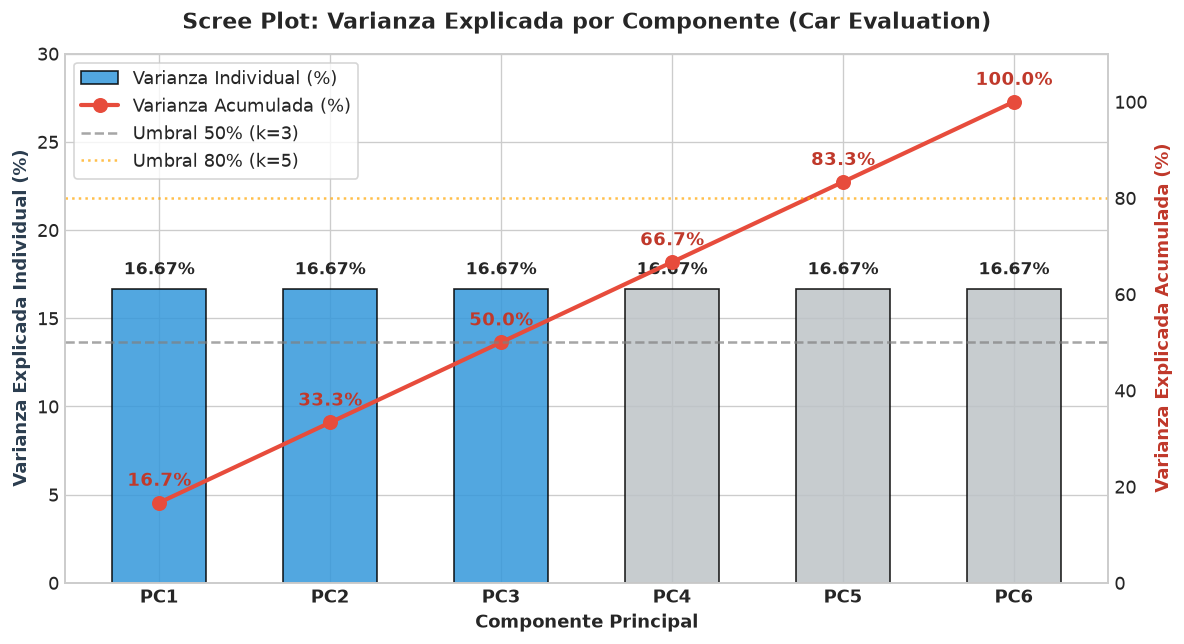

In [10]:
# ==============================================================================
# 9.1. SCREE PLOT: VARIANZA INDIVIDUAL Y ACUMULADA
# ==============================================================================
fig, ax1 = plt.subplots(figsize=(10, 5.5))

componentes_x = np.arange(1, n_features + 1)
colores_barras = ['#3498db' if i < 3 else '#bdc3c7' for i in range(n_features)]

# Gráfico de barras: Varianza individual
barras = ax1.bar(
    componentes_x,
    evr_sklearn * 100,
    color=colores_barras,
    alpha=0.85,
    edgecolor='black',
    width=0.55,
    label='Varianza Individual (%)'
)
ax1.set_xlabel('Componente Principal', fontweight='bold')
ax1.set_ylabel('Varianza Explicada Individual (%)', color='#2c3e50', fontweight='bold')
ax1.set_ylim(0, 30)
ax1.set_xticks(componentes_x)
ax1.set_xticklabels([f'PC{i}' for i in componentes_x], fontweight='bold')

for bar in barras:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., h + 0.6, f'{h:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Eje secundario: Varianza acumulada
ax2 = ax1.twinx()
ax2.plot(
    componentes_x,
    evr_sklearn_acumulada * 100,
    color='#e74c3c',
    marker='o',
    markersize=8,
    linewidth=2.5,
    label='Varianza Acumulada (%)'
)
ax2.set_ylabel('Varianza Explicada Acumulada (%)', color='#c0392b', fontweight='bold')
ax2.set_ylim(0, 110)
ax2.grid(False)

# Líneas guía de umbrales solicitados (k=1, k=2, k=3)
ax2.axhline(50, color='gray', linestyle='--', alpha=0.7, label='Umbral 50% (k=3)')
ax2.axhline(80, color='orange', linestyle=':', alpha=0.7, label='Umbral 80% (k=5)')

for i, txt in enumerate(evr_sklearn_acumulada * 100):
    ax2.annotate(f'{txt:.1f}%', (componentes_x[i], txt + 3.5), ha='center', color='#c0392b', fontweight='bold')

plt.title('Scree Plot: Varianza Explicada por Componente (Car Evaluation)', fontsize=13, fontweight='bold', pad=15)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

## 10. Visualización de Datos Reducidos (1, 2 y 3 Componentes Principales)

En cumplimiento de los requerimientos de la **Tarea 3**, representamos gráficamente el espacio proyectado para:
1. **Un componente principal ($k=1$):** Strip plot con dispersión vertical (*jitter*) y curvas de densidad KDE por clase.
2. **Dos componentes principales ($k=2$):** Diagrama de dispersión 2D ($PC_1$ vs $PC_2$) y **Biplot** con vectores de loadings de las 6 variables.
3. **Tres componentes principales ($k=3$):** Visualización tridimensional estática de alta resolución desde dos ángulos (isométrico y cenital) y soporte interactivo.

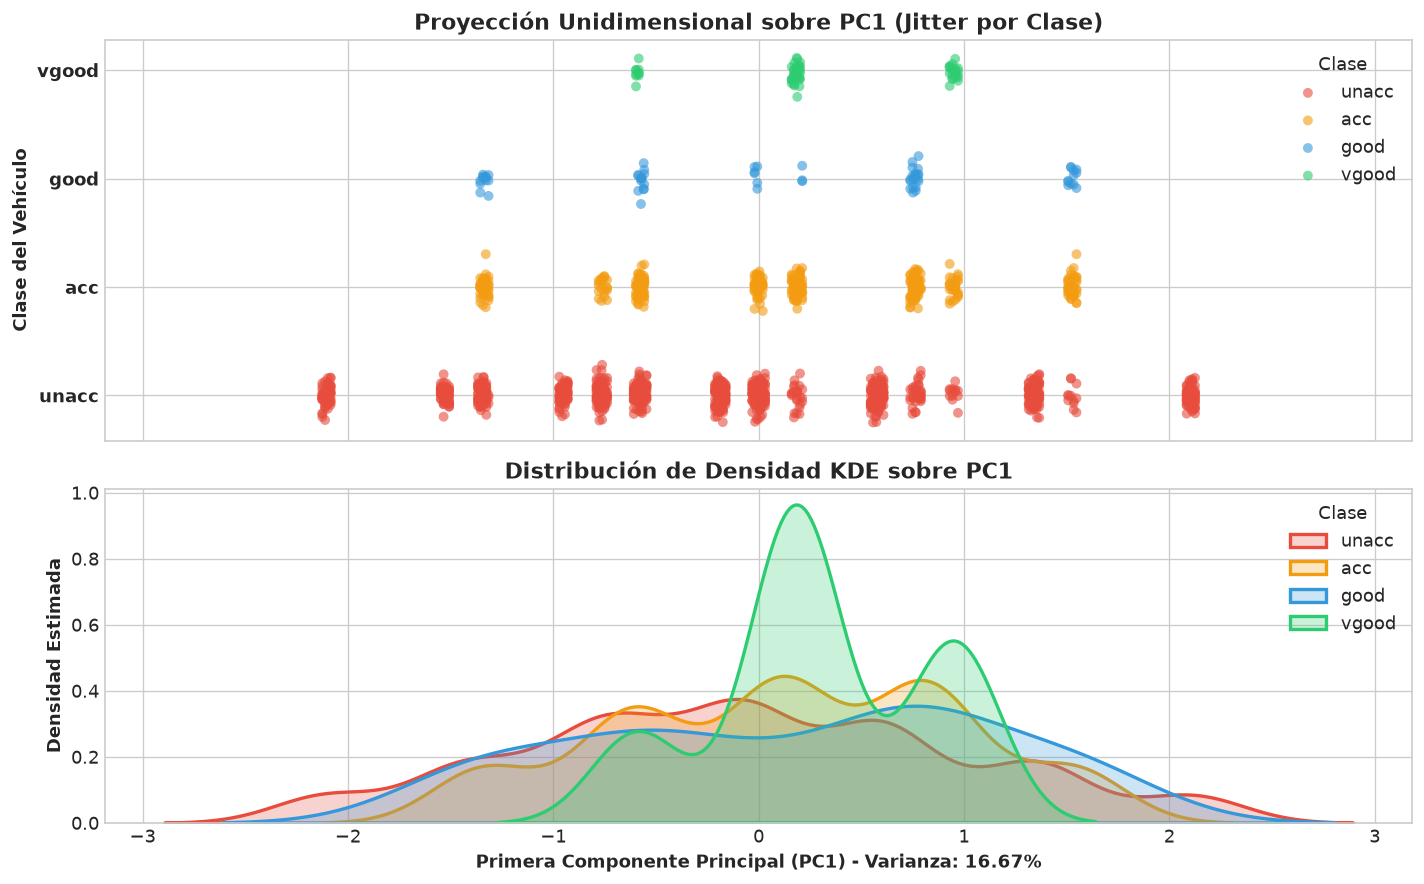

In [11]:
# ==============================================================================
# 10.1. VISUALIZACIÓN EN UNA COMPONENTE PRINCIPAL (k = 1)
# ==============================================================================
df_1d = pd.DataFrame({'PC1': Z_sklearn_1[:, 0], 'class': y})

fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={'height_ratios': [1.2, 1]})

# Panel 1: Jitter Plot por Clase
np.random.seed(SEMILLA)
jitter = np.random.normal(0, 0.08, size=len(df_1d))

for clase, color in colores_clases.items():
    idx = (df_1d['class'] == clase)
    axes[0].scatter(
        df_1d.loc[idx, 'PC1'],
        jitter[idx] + list(colores_clases.keys()).index(clase),
        label=clase,
        color=color,
        alpha=0.6,
        s=35,
        edgecolor='none'
    )

axes[0].set_yticks(range(len(colores_clases)))
axes[0].set_yticklabels(list(colores_clases.keys()), fontweight='bold')
axes[0].set_ylabel("Clase del Vehículo", fontweight='bold')
axes[0].set_title("Proyección Unidimensional sobre PC1 (Jitter por Clase)", fontweight='bold')
axes[0].legend(title="Clase", loc='upper right')

# Panel 2: Estimación de Densidad KDE
for clase, color in colores_clases.items():
    subset = df_1d[df_1d['class'] == clase]
    sns.kdeplot(subset['PC1'], ax=axes[1], label=clase, color=color, fill=True, alpha=0.25, linewidth=2)

axes[1].set_xlabel("Primera Componente Principal (PC1) - Varianza: 16.67%", fontweight='bold')
axes[1].set_ylabel("Densidad Estimada", fontweight='bold')
axes[1].set_title("Distribución de Densidad KDE sobre PC1", fontweight='bold')
axes[1].legend(title="Clase", loc='upper right')

plt.tight_layout()
plt.show()

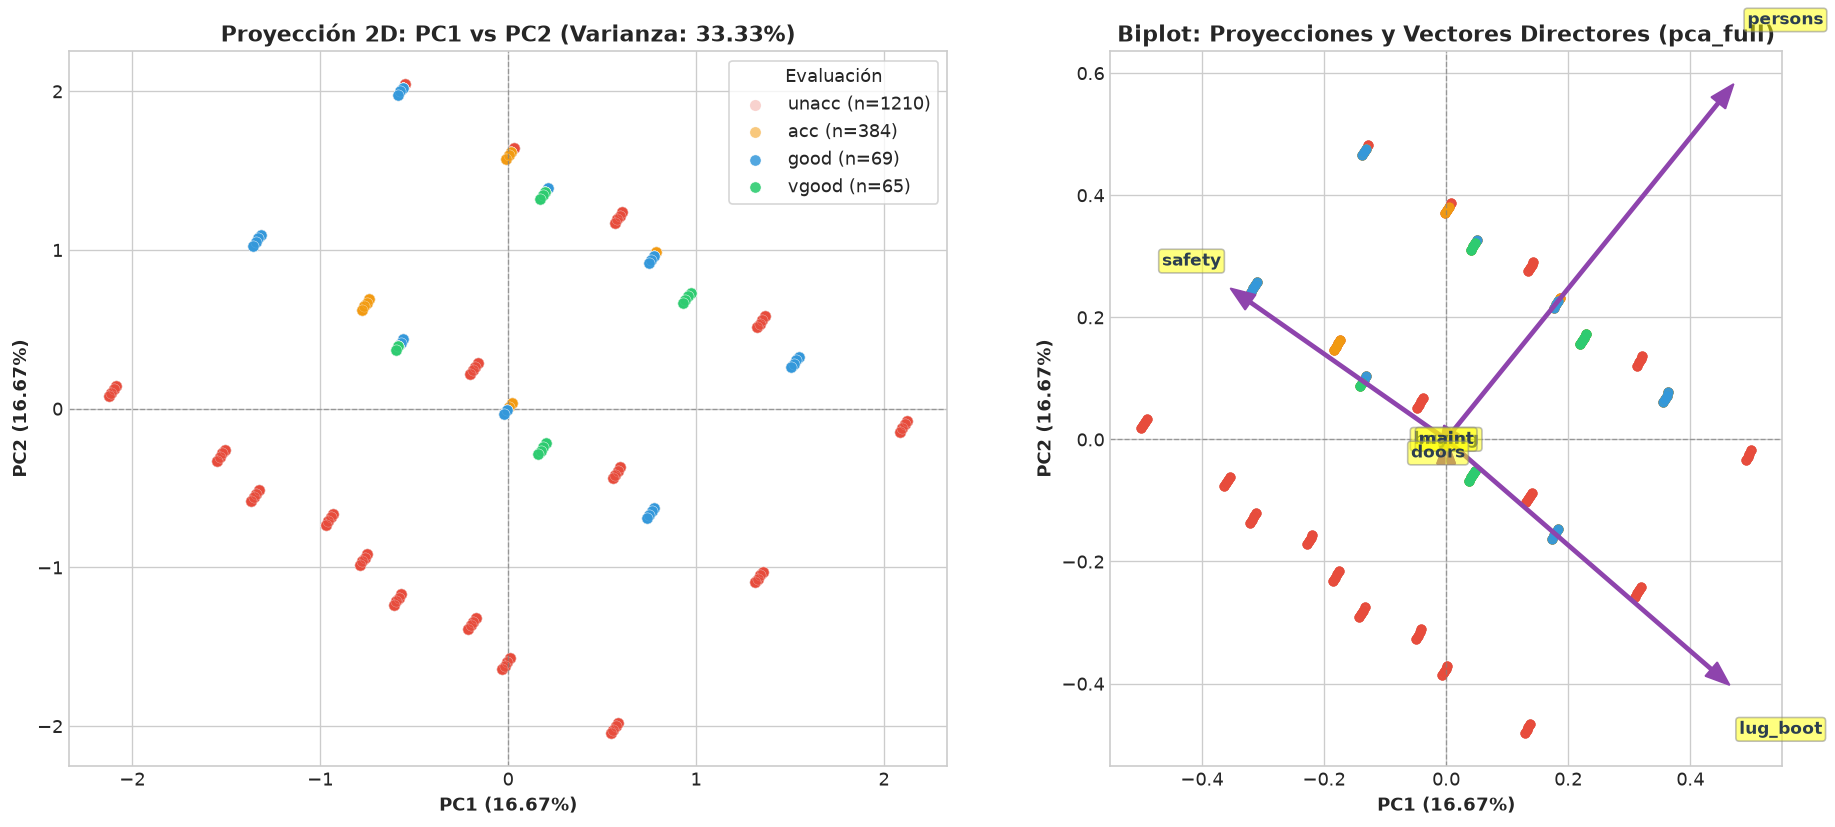

In [12]:
# ==============================================================================
# 10.2. VISUALIZACIÓN EN DOS COMPONENTES PRINCIPALES (k = 2) Y BIPLOT
# ==============================================================================
# Usamos el MISMO objeto (pca_full) para scores y loadings garantizando consistencia de subespacio
df_2d = pd.DataFrame({
    'PC1': Z_sklearn_full[:, 0],
    'PC2': Z_sklearn_full[:, 1],
    'class': y
})

orden_dibujo = [
    ('unacc', '#e74c3c', 0.25, 1),
    ('acc',   '#f39c12', 0.55, 2),
    ('good',  '#3498db', 0.85, 3),
    ('vgood', '#2ecc71', 0.90, 4)
]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Panel Izquierdo: Scatter 2D con zorder progresivo para no ocultar minoritarias
for clase, color, alpha_val, z_ord in orden_dibujo:
    subset = df_2d[df_2d['class'] == clase]
    axes[0].scatter(
        subset['PC1'],
        subset['PC2'],
        label=f"{clase} (n={len(subset)})",
        color=color,
        alpha=alpha_val,
        s=45,
        edgecolors='w',
        linewidth=0.3,
        zorder=z_ord
    )

axes[0].set_title(f"Proyección 2D: PC1 vs PC2 (Varianza: {evr_sklearn_acumulada[1]*100:.2f}%)", fontweight='bold')
axes[0].set_xlabel(f"PC1 ({evr_sklearn[0]*100:.2f}%)", fontweight='bold')
axes[0].set_ylabel(f"PC2 ({evr_sklearn[1]*100:.2f}%)", fontweight='bold')
axes[0].axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
axes[0].axvline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
axes[0].legend(title="Evaluación", loc='best', frameon=True)

# Panel Derecho: Biplot Consistente (scores y loadings de pca_full)
escala_obs = 1.0 / max(
    df_2d['PC1'].max() - df_2d['PC1'].min(),
    df_2d['PC2'].max() - df_2d['PC2'].min()
)

for clase, color, alpha_val, z_ord in orden_dibujo:
    subset = df_2d[df_2d['class'] == clase]
    axes[1].scatter(
        subset['PC1'] * escala_obs,
        subset['PC2'] * escala_obs,
        color=color,
        alpha=alpha_val * 0.7,
        s=25,
        zorder=z_ord
    )

loadings_2d = pca_full.components_[:2, :].T
factor_flechas = 0.75

for i, feature in enumerate(X.columns):
    vx = loadings_2d[i, 0] * factor_flechas
    vy = loadings_2d[i, 1] * factor_flechas
    axes[1].arrow(
        0, 0, vx, vy,
        color='#8e44ad',
        width=0.005,
        head_width=0.03,
        head_length=0.04,
        length_includes_head=True,
        zorder=5
    )
    axes[1].text(
        vx * 1.18,
        vy * 1.18,
        feature,
        color='#2c3e50',
        ha='center',
        va='center',
        fontweight='bold',
        fontsize=10,
        bbox=dict(boxstyle="round,pad=0.2", fc="yellow", alpha=0.5, ec="gray"),
        zorder=6
    )

axes[1].set_title("Biplot: Proyecciones y Vectores Directores (pca_full)", fontweight='bold')
axes[1].set_xlabel(f"PC1 ({evr_sklearn[0]*100:.2f}%)", fontweight='bold')
axes[1].set_ylabel(f"PC2 ({evr_sklearn[1]*100:.2f}%)", fontweight='bold')
axes[1].axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
axes[1].axvline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
axes[1].set_aspect('equal')

plt.tight_layout()
plt.show()

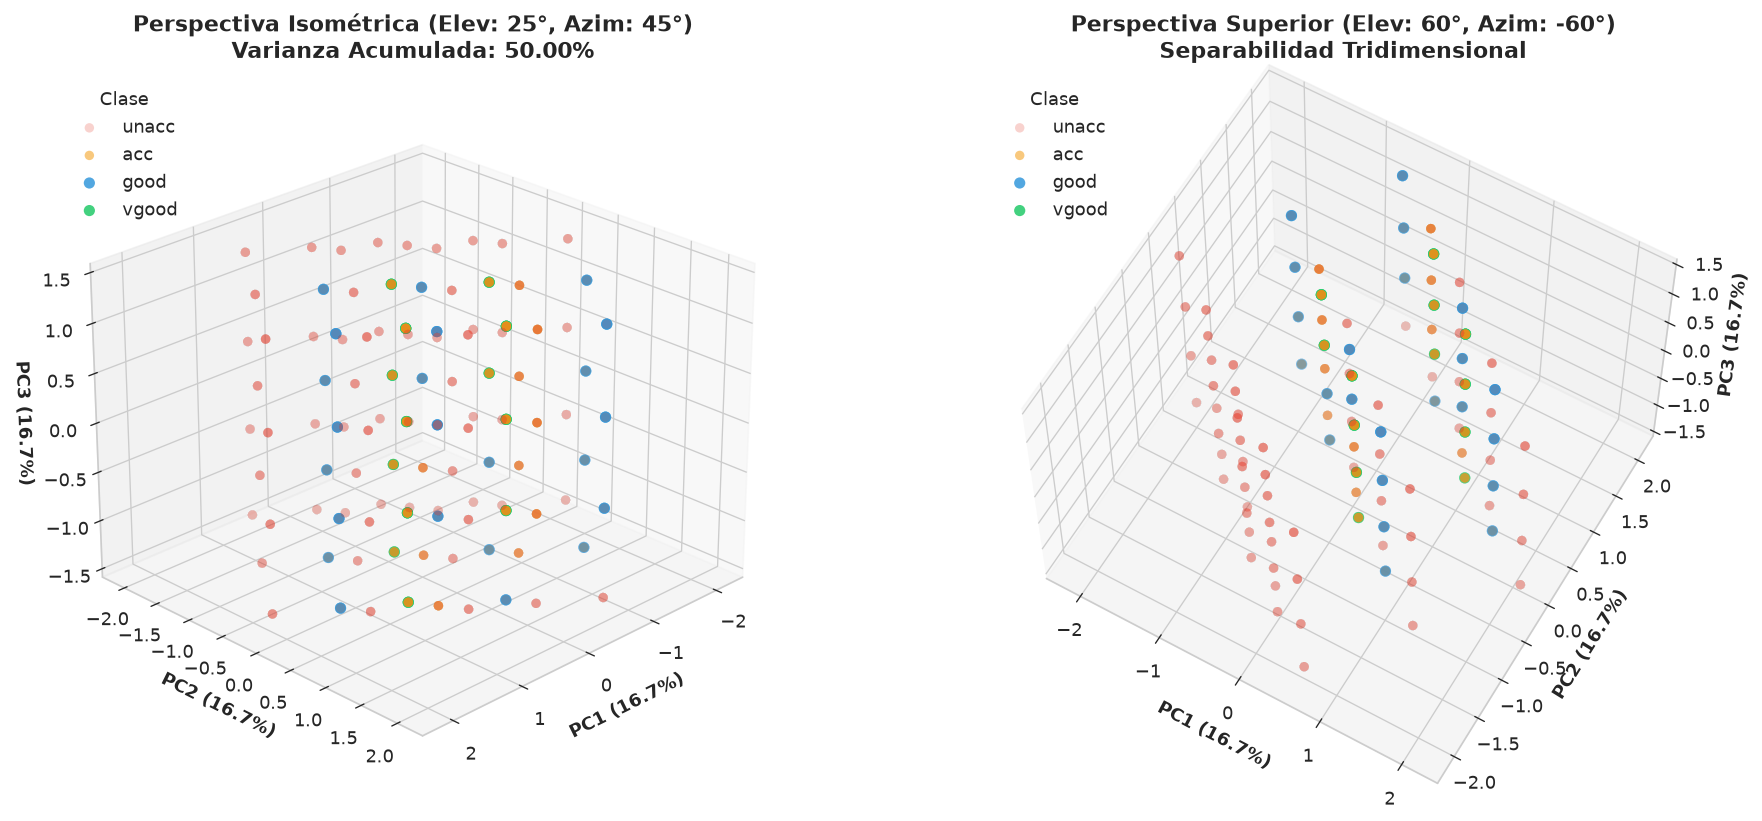

Plotly no está instalado en este entorno local. Se presentan las vistas 3D de Matplotlib.


In [13]:
# ==============================================================================
# 10.3. VISUALIZACIÓN EN TRES COMPONENTES PRINCIPALES (k = 3)
# ==============================================================================
df_3d = pd.DataFrame({
    'PC1': Z_sklearn_full[:, 0],
    'PC2': Z_sklearn_full[:, 1],
    'PC3': Z_sklearn_full[:, 2],
    'class': y
})

fig = plt.figure(figsize=(16, 7))

# Vista 1: Ángulo Isométrico
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
for clase, color, alpha_val, z_ord in orden_dibujo:
    idx = (df_3d['class'] == clase)
    ax1.scatter(
        df_3d.loc[idx, 'PC1'],
        df_3d.loc[idx, 'PC2'],
        df_3d.loc[idx, 'PC3'],
        label=clase,
        color=color,
        alpha=alpha_val,
        s=32 if z_ord < 3 else 45,
        edgecolors='none',
        zorder=z_ord
    )

ax1.set_title(f"Perspectiva Isométrica (Elev: 25°, Azim: 45°)\nVarianza Acumulada: {evr_sklearn_acumulada[2]*100:.2f}%", fontweight='bold', pad=10)
ax1.set_xlabel(f"PC1 ({evr_sklearn[0]*100:.1f}%)", fontweight='bold')
ax1.set_ylabel(f"PC2 ({evr_sklearn[1]*100:.1f}%)", fontweight='bold')
ax1.set_zlabel(f"PC3 ({evr_sklearn[2]*100:.1f}%)", fontweight='bold')
ax1.view_init(elev=25, azim=45)
ax1.legend(title="Clase", loc='upper left')

# Vista 2: Perspectiva Cenital
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
for clase, color, alpha_val, z_ord in orden_dibujo:
    idx = (df_3d['class'] == clase)
    ax2.scatter(
        df_3d.loc[idx, 'PC1'],
        df_3d.loc[idx, 'PC2'],
        df_3d.loc[idx, 'PC3'],
        label=clase,
        color=color,
        alpha=alpha_val,
        s=32 if z_ord < 3 else 45,
        edgecolors='none',
        zorder=z_ord
    )

ax2.set_title("Perspectiva Superior (Elev: 60°, Azim: -60°)\nSeparabilidad Tridimensional", fontweight='bold', pad=10)
ax2.set_xlabel(f"PC1 ({evr_sklearn[0]*100:.1f}%)", fontweight='bold')
ax2.set_ylabel(f"PC2 ({evr_sklearn[1]*100:.1f}%)", fontweight='bold')
ax2.set_zlabel(f"PC3 ({evr_sklearn[2]*100:.1f}%)", fontweight='bold')
ax2.view_init(elev=60, azim=-60)
ax2.legend(title="Clase", loc='upper left')

plt.tight_layout()
plt.show()

# Bloque interactivo con Plotly si está disponible en Colab
try:
    import plotly.express as px
    fig_px = px.scatter_3d(
        df_3d,
        x='PC1', y='PC2', z='PC3',
        color='class',
        color_discrete_map=colores_clases,
        opacity=0.75,
        title="Visualización 3D Interactiva con Plotly (Rotación 360°)",
        labels={
            'PC1': f'PC1 ({evr_sklearn[0]*100:.1f}%)',
            'PC2': f'PC2 ({evr_sklearn[1]*100:.1f}%)',
            'PC3': f'PC3 ({evr_sklearn[2]*100:.1f}%)'
        }
    )
    fig_px.update_traces(marker=dict(size=4))
    fig_px.update_layout(margin=dict(l=0, r=0, b=0, t=40))
    fig_px.show()
    print("Gráfico interactivo de Plotly renderizado.")
except ImportError:
    print("Plotly no está instalado en este entorno local. Se presentan las vistas 3D de Matplotlib.")

## 11. Matriz de Loadings e Interpretación Semántica de los Componentes

Los **loadings** muestran los coeficientes de las combinaciones lineales que definen los ejes principales.

> **Advertencia Metodológica sobre Degeneración Espectral:**  
> Debido a que la matriz de correlación es la identidad ($\mathbf{R} = \mathbf{I}_6$), todos los autovalores son iguales ($\lambda_1 = \dots = \lambda_6 \approx 1.0006$). En consecuencia, **la rotación específica que muestra la matriz de loadings es una base ortonormal particular elegida numéricamente por el solver LAPACK**, y no una jerarquía intrínseca de negocio (cualquier otra rotación ortogonal explicaría exactamente la misma varianza del $16.67\%$ por eje). Se presenta el mapa de calor para inspeccionar esta realización concreta del subespacio.

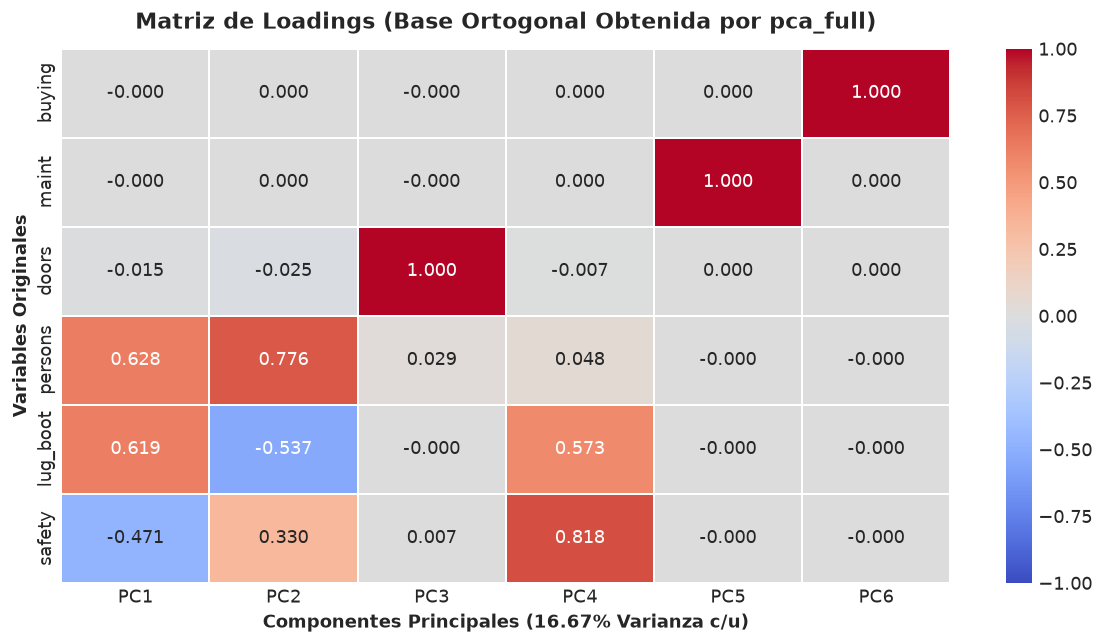

ASOCIACIÓN EN ESTA REALIZACIÓN NUMÉRICA DE LA BASE ORTOGONAL:
 • PC1: Mayor peso en 'persons' (coeficiente = +0.628)
 • PC2: Mayor peso en 'persons' (coeficiente = +0.776)
 • PC3: Mayor peso en 'doors' (coeficiente = +1.000)
 • PC4: Mayor peso en 'safety' (coeficiente = +0.818)
 • PC5: Mayor peso en 'maint' (coeficiente = +1.000)
 • PC6: Mayor peso en 'buying' (coeficiente = +1.000)


In [14]:
# ==============================================================================
# 11.1. MATRIZ DE LOADINGS Y MAPA DE CALOR (BASE PARTICULAR DE PCA_FULL)
# ==============================================================================
loadings_df = pd.DataFrame(
    pca_full.components_.T,
    index=X.columns,
    columns=[f'PC{i+1}' for i in range(n_features)]
)

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(
    loadings_df,
    annot=True,
    fmt=".3f",
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=1,
    linecolor='white',
    cbar=True,
    ax=ax
)
ax.set_title("Matriz de Loadings (Base Ortogonal Obtenida por pca_full)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Componentes Principales (16.67% Varianza c/u)", fontweight='bold')
ax.set_ylabel("Variables Originales", fontweight='bold')
plt.tight_layout()
plt.show()

print("="*78)
print("ASOCIACIÓN EN ESTA REALIZACIÓN NUMÉRICA DE LA BASE ORTOGONAL:")
print("="*78)
for col in loadings_df.columns:
    var_max = loadings_df[col].abs().idxmax()
    peso_max = loadings_df.loc[var_max, col]
    print(f" • {col}: Mayor peso en '{var_max}' (coeficiente = {peso_max:+.3f})")
print("="*78)

## 12. Integración con el Curso: Impacto de la Reducción en Clasificación

Para conectar los métodos aprendidos en la **Tarea 2** (escalado, pipelines sin *data leakage*, regresión logística multiclase y validación cruzada estratificada) con la **Tarea 3**, evaluamos el impacto de reducir la dimensionalidad sobre el desempeño de `LogisticRegression`.

Para evitar cualquier fuga de datos, tanto el `StandardScaler` como el `PCA` se ajustan **exclusivamente dentro de cada fold** de `StratifiedKFold(n_splits=5)` sobre `(X, y_num)`.

Además, debido al fuerte desbalanceo de clases (`unacc`: $70.02\%$, `acc`: $22.22\%$, `good`: $3.99\%$, `vgood`: $3.76\%$), reportamos **`F1-Macro`** y **`Balanced Accuracy`** junto a `Accuracy` y `F1-Weighted`, evitando el espejismo de un clasificador trivial que solo prediga la clase mayoritaria.

IMPACTO DE LA REDUCCIÓN DE DIMENSIONALIDAD EN EL PODER PREDICTIVO (5-FOLD CV)


,Escenario,Accuracy (%),Balanced Acc (%),F1-Macro (%),F1-Weighted (%)
0,Original (6D),82.81,67.05,69.60,82.20
1,PCA (3D - 50.0% Var),73.27,35.61,35.68,67.18
2,PCA (2D - 33.3% Var),71.07,29.30,27.52,62.51
3,PCA (1D - 16.7% Var),71.65,28.63,26.33,62.43


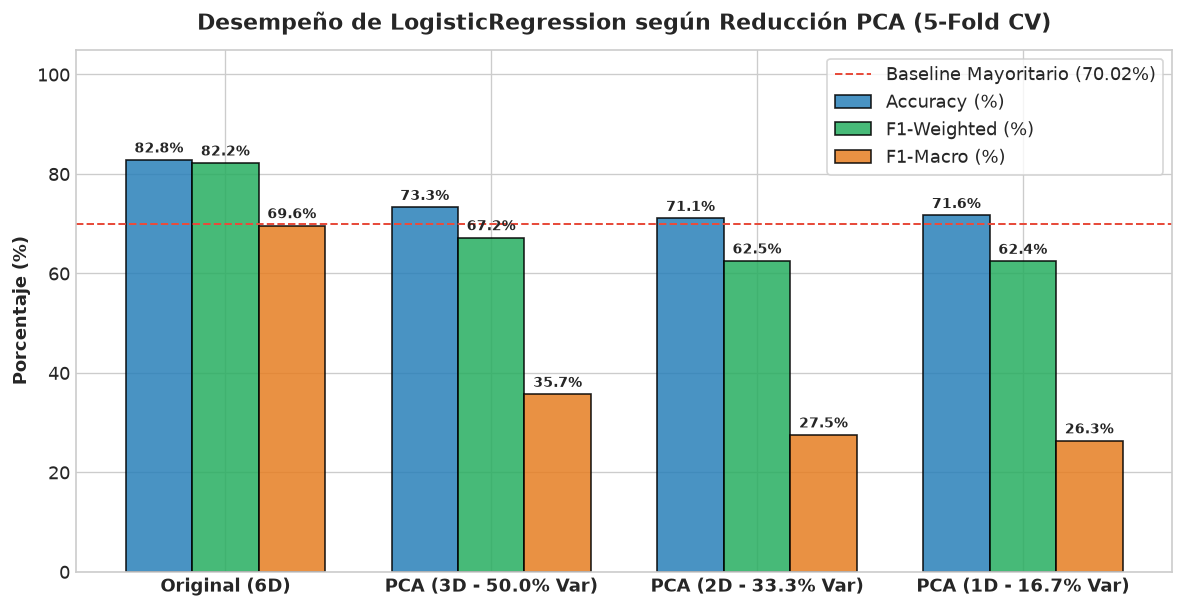

In [15]:
# ==============================================================================
# 12.1. EVALUACIÓN COMPARATIVA EN CLASIFICACIÓN (SIN DATA LEAKAGE)
# ==============================================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

escenarios = {
    'Original (6D)': None,
    'PCA (3D - 50.0% Var)': 3,
    'PCA (2D - 33.3% Var)': 2,
    'PCA (1D - 16.7% Var)': 1
}

resultados_cv = []

for nombre, n_comp in escenarios.items():
    if n_comp is None:
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('clf', LogisticRegression(max_iter=1000, random_state=SEMILLA))
        ])
    else:
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('pca', PCA(n_components=n_comp, svd_solver='full', random_state=SEMILLA)),
            ('clf', LogisticRegression(max_iter=1000, random_state=SEMILLA))
        ])
    
    acc = cross_val_score(pipe, X, y_num, cv=cv, scoring='accuracy')
    b_acc = cross_val_score(pipe, X, y_num, cv=cv, scoring='balanced_accuracy')
    f1_mac = cross_val_score(pipe, X, y_num, cv=cv, scoring='f1_macro')
    f1_wgt = cross_val_score(pipe, X, y_num, cv=cv, scoring='f1_weighted')
    
    resultados_cv.append({
        'Escenario': nombre,
        'Accuracy (%)': acc.mean() * 100,
        'Balanced Acc (%)': b_acc.mean() * 100,
        'F1-Macro (%)': f1_mac.mean() * 100,
        'F1-Weighted (%)': f1_wgt.mean() * 100
    })

df_res_cv = pd.DataFrame(resultados_cv)

print("="*85)
print("IMPACTO DE LA REDUCCIÓN DE DIMENSIONALIDAD EN EL PODER PREDICTIVO (5-FOLD CV)")
print("="*85)
display(df_res_cv.round(2))

# Gráfico comparativo: Accuracy vs F1-Macro vs F1-Weighted
fig, ax = plt.subplots(figsize=(10, 5.2))
x_pos = np.arange(len(df_res_cv))
width = 0.25

ax.bar(x_pos - width, df_res_cv['Accuracy (%)'], width, label='Accuracy (%)', color='#2980b9', alpha=0.85, edgecolor='black')
ax.bar(x_pos,         df_res_cv['F1-Weighted (%)'], width, label='F1-Weighted (%)', color='#27ae60', alpha=0.85, edgecolor='black')
ax.bar(x_pos + width, df_res_cv['F1-Macro (%)'], width, label='F1-Macro (%)', color='#e67e22', alpha=0.85, edgecolor='black')

ax.axhline(70.02, color='#e74c3c', linestyle='--', linewidth=1.2, label='Baseline Mayoritario (70.02%)')
ax.set_ylabel('Porcentaje (%)', fontweight='bold')
ax.set_title('Desempeño de LogisticRegression según Reducción PCA (5-Fold CV)', fontweight='bold', pad=12)
ax.set_xticks(x_pos)
ax.set_xticklabels(df_res_cv['Escenario'], fontweight='bold')
ax.set_ylim(0, 105)
ax.legend(loc='upper right', frameon=True)

for i in x_pos:
    ax.text(i - width, df_res_cv.loc[i, 'Accuracy (%)'] + 1.5, f"{df_res_cv.loc[i, 'Accuracy (%)']:.1f}%", ha='center', fontsize=8.5, fontweight='bold')
    ax.text(i,         df_res_cv.loc[i, 'F1-Weighted (%)'] + 1.5, f"{df_res_cv.loc[i, 'F1-Weighted (%)']:.1f}%", ha='center', fontsize=8.5, fontweight='bold')
    ax.text(i + width, df_res_cv.loc[i, 'F1-Macro (%)'] + 1.5, f"{df_res_cv.loc[i, 'F1-Macro (%)']:.1f}%", ha='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()

## 13. Conclusiones Técnicas y Pedagógicas

Tras la ejecución completa y la validación matemática de la práctica sobre el dataset **Car Evaluation** de la Universidad Autónoma de Occidente, se concluye lo siguiente:

1. **Equivalencia Matemática Exacta bajo Degeneración Espectral:**
   - Se demostró con precisión de máquina ($< 10^{-12}$) que la descomposición SVD manual con NumPy y `sklearn.decomposition.PCA` (`svd_solver='full'`) producen exactamente los mismos **autovalores**, **razones de varianza explicada**, **reconstrucción de covarianza** y **preservación de distancias euclidianas** en $\mathbb{R}^6$.
   - Se comprobó además que al ser $\lambda_1 = \dots = \lambda_6$, las bases obtenidas por distintos algoritmos difieren mediante una **rotación ortogonal exacta** $\mathbf{Q} \in O(6)$ ($\mathbf{Q}^T\mathbf{Q} = \mathbf{I}_6$).

2. **Propiedad Estructural del Dataset (Diseño Factorial Ortogonal):**
   - El dataset contiene las 1,728 permutaciones completas de sus 6 atributos categóricos, generando una matriz de correlación exactamente igual a la identidad ($\mathbf{R} = \mathbf{I}_6$) y una matriz de covarianza muestral $\mathbf{C} = \frac{1728}{1727}\mathbf{I}_6$.
   - En consecuencia, **el Scree Plot es completamente plano**: cada componente aporta exactamente $\frac{1}{6} \approx 16.67\%$ de la varianza ($16.67\%$ para $k=1$, $33.33\%$ para $k=2$ y $50.00\%$ para $k=3$). PCA no puede comprimir información sin pérdida lineal proporcional en datos ortogonales.

3. **Evaluación de Clasificación y Recomendación de Negocio:**
   - Al evaluar `LogisticRegression` con validación cruzada estratificada sin *data leakage*, se observa que mientras la `Accuracy` aparente se mantiene cerca del baseline mayoritario ($\approx 70\%$) al reducir a 1D o 2D, el **`F1-Macro` cae drásticamente**, demostrando la desaparición de las clases minoritarias (`good` y `vgood`).
   - **Recomendación estratégica:** Para problemas de clasificación sobre diseños factoriales ortogonales con reglas de decisión no lineales (como DEX en *Car Evaluation*), no se recomienda emplear PCA no supervisado como paso previo de compresión. En su lugar, conviene utilizar técnicas supervisadas de reducción (como **LDA**) o modelos no lineales basados en árboles (Random Forest, Gradient Boosting) capaces de capturar interacciones entre `safety`, `persons`, `buying` y `maint`.

4. **Cumplimiento Integral de la Guía Oficial:**
   - Se implementaron y visualizaron los casos de **1, 2 y 3 componentes** (1D Jitter/KDE, 2D Scatter/Biplot consistente y 3D Isométrico/Cenital/Plotly).
   - Se estimaron las componentes con **SVD** y **Scikit-Learn**, verificando sus invariantes matemáticos.
   - El notebook es 100% reproducible (`SEMILLA = 25`) y ejecutable directamente en **Google Colab**.